# ACESO v2 — training on a two-million-nucleus corpus

The v1 model learns one reference dataset (see the ACESO tutorial). v2 keeps the same idea — any gene
subset maps into one chromatin-state space — and trains it on a corpus instead: **2,038,905 human
nuclei**, 147 samples, 13 organs, fetal and adult, each with RNA and ATAC in the same nucleus.

Three things change, and each has a reason that was measured rather than assumed:

| Change | Why | Epione |
|---|---|---|
| the store is the contract | at 147 samples the commonest silent failure is a mis-joined row order, so one `cells.tsv` fixes the row order for every array | `epi.models.aceso.TrainingStore`, `build_training_store` |
| two views per cell, the wide one a stop-gradient teacher | a subset-only objective can only teach invariance to missing genes, never selectivity about which genes carry the state | `epi.models.aceso.train_v2_encoder` |
| a per-gene RNA head beside the 32 bp ATAC head, and named within-type axes as explicit inputs | a within-type shift of 0.73 SD arrives in a 512-dimensional `z` as a 0.0013 cosine wiggle, so it needs an axis of its own | `epi.models.aceso.train_v2_decoder`, `build_axes`, `ExonMasks` |

**Data.** The corpus is built from two public resources — a human developmental multiome atlas and
ENCODE's adult multiomes — ingested per sample and consolidated into one store. This notebook reads
the store that the paper's model was trained on; set `$ACESO_STORE` to your own.

## Setup

In [1]:
import json
import os
import pathlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from epione.models import aceso

aceso.paper_style()
ROOT = pathlib.Path(os.environ.get("EPIONE_ROOT", "."))
STORE = pathlib.Path(os.environ.get("ACESO_STORE", ROOT / "data/train_v2"))
print("store:", STORE, "-", "present" if (STORE / "cells.tsv").exists() else "not built here")

store: /scratch/users/steorra/analysis/25_epione/data/train_v2 - present


## Part 1 · The store is the contract

`build_training_store` consolidates the ingested per-sample files into one directory:

```
cells.tsv        one row per cell: cell_id, corpus, sample, organ, cell_type, stage_or_age, n_umi, n_genes
rna.h5ad         cells x scGPT-vocab genes, int32 counts, symbol-keyed
z_epiagent.npy   cells x 512, row i == cells.tsv row i
fragments/       per-sample tabix'd fragments, in real barcode space
splits.json      train / val / test BY SAMPLE, never by cell
manifest.json    sizes, md5s and the provenance of every piece
```

Two decisions inside it are worth knowing. The RNA store is **symbol-keyed** because scGPT's
vocabulary is symbols, and going back to symbols from an Ensembl index has to *sum* duplicate rows
rather than pick one; on one sample 24,540 of 38,705 genes are in the vocabulary and carry 96.9 % of
the UMIs. And the splits are **by sample**: cells from one 10x channel share ambient RNA, barcode
collisions and batch, so a cell-level split leaks all three.

```bash
python -m epione.models.aceso._store --corpus hdma,encode --all --out data/train_v2
```

`TrainingStore` reads it without touching the count matrix.

In [2]:
if (STORE / "cells.tsv").exists():
    store = aceso.TrainingStore(STORE)
    print(f"{len(store.cells):,} cells x {len(store.genes):,} genes")
    print(store.summary())
    print("\nheld out:", {k: len(v) for k, v in store.splits.items()})
else:
    store = None
    print("no store here; build one with aceso.build_training_store(StoreConfig(...))")

2,038,905 cells x 39,028 genes


          cells  samples  organs  cells_with_fragments
corpus                                                
encode  1472631       97      13               1472631
hdma     566274       50       9                566274

held out: {'test': 12, 'val': 12, 'train': 123}


In [3]:
if store is not None:
    print(store.cells[["corpus", "sample", "organ", "cell_type", "stage_or_age", "n_umi"]].head())
    print("\ncells per organ:")
    print(store.cells.organ.value_counts().head(13).to_string())

  corpus                sample  organ       cell_type stage_or_age  n_umi
0   hdma  T014_b11_Heart_PCW18  Heart     fibroblasts        PCW18   2666
1   hdma  T014_b11_Heart_PCW18  Heart     fibroblasts        PCW18   2156
2   hdma  T014_b11_Heart_PCW18  Heart     endothelial        PCW18  18993
3   hdma  T014_b11_Heart_PCW18  Heart  cardiomyocytes        PCW18   1768
4   hdma  T014_b11_Heart_PCW18  Heart     endothelial        PCW18  13742

cells per organ:
organ
heart            1098818
Heart             120254
Muscle             92542
ovary              91839
Brain              75597
Liver              71807
Eye                64095
Skin               57801
pancreas           42157
Thymus             41702
adrenal gland      40295
muscle             36439
lung               34919


## Part 2 · Named within-type axes

A cell type is not one state. The axes are signed contrasts between curated marker sets, scored on
the log-normalised RNA and standardised inside the tissue where the contrast means something:

    score = mean(log1p CPM of the + markers) - mean(log1p CPM of the - markers)

They are deliberately not principal components: an axis that cannot be named cannot be checked
against biology. Tissue scope is part of the definition, so each axis ships a mask and a cell outside
its tissue gets value 0 with mask 0 — the decoder multiplies by the mask, so an undefined axis
contributes nothing rather than a confident zero.

In [4]:
for name, a in aceso.AXES.items():
    print(f"{name:9s} tissue={a['tissue']}  {a['note']}")
    print(f"           + {', '.join(a['pos'][:6])} ...")
    print(f"           - {', '.join(a['neg'][:6])} ...")

chamber   tissue=['heart']  ventricular (+) vs atrial (-)
           + MYH7, MYL2, IRX4, HEY2, FHL2, MYL3 ...
           - NPPA, MYL7, MYL4, SLN, GJA5, KCNJ3 ...
cycle     tissue=None  proliferative (+) vs arrested (-); defined in every tissue
           + MKI67, TOP2A, CCNB1, CDK1, BUB1, AURKA ...
           - CDKN1A, CDKN1B, CDKN2A, RB1, GAS1, GADD45A ...


In [5]:
if store is not None and store.axes is not None:
    names = list(store.axes["names"])
    score, mask = store.axes["score"], store.axes["mask"]
    for i, n in enumerate(names):
        d = mask[:, i] > 0
        print(f"{n:9s} defined in {d.sum():>9,} cells ({d.mean():.1%}), "
              f"range {score[d, i].min():+.2f} .. {score[d, i].max():+.2f}")
else:
    print("no axes.npz in the store; write one with aceso.build_axes(STORE)")

chamber   defined in 1,219,072 cells (59.8%), range -5.51 .. +3.04
cycle     defined in 2,038,905 cells (100.0%), range -6.47 .. +10.69


## Part 3 · Exonic masks, and why the RNA head needs no BAM

The corpus is 3'-biased UMI data. A "coverage track" built from it is a spike near the 3' end plus
library artefacts, so fitting one teaches 10x chemistry rather than regulation. The informative
quantity is per-gene expression in that cell state, which is what the count matrix already holds, so
the RNA head pools the trunk embedding over a gene's **exons** and reads out one log-rate per gene.
`ExonMasks` builds those pooling domains from GENCODE, merged across isoforms.

In [6]:
masks = pathlib.Path(os.environ.get("EXON_MASKS", ROOT / "data/exon_masks/exons_hg38.npz"))
if masks.exists():
    em = aceso.ExonMasks(masks, gene_list=(store.genes if store is not None else None), bin_size=32)
    cols, M = em.window("chr14", 23_380_000, 23_380_000 + 196_608)
    print(f"{len(cols)} genes overlap the window; exonic bins per gene: "
          f"median {np.median(M.sum(1)):.0f} of {M.shape[1]}")
else:
    print(f"no masks at {masks}; build them with "
          f"aceso.build_exon_masks('gencode.v41.annotation.gff3.gz', 'data/exon_masks')")

10 genes overlap the window; exonic bins per gene: median 103 of 6144


## Part 4 · Stage 1, two views of each cell

Each cell is read twice: an arbitrary gene subset, and a wide random view that acts as a
stop-gradient teacher.

    L = L(z_sub, z_target) + L(z_wide, z_target) + lam * L(z_sub, sg[z_wide])

Subsets are half uniform, half structured; no vendor panel is trained on, so "any gene set" stays a
testable claim and the real panels move entirely to evaluation. `max_len` 1200 and random truncation
are scGPT's own pretraining settings and are kept — scGPT's pretraining task already *is* "infer the
cell state from a random subset", which is why panel-agnostic training worked in v1 at all.

In [7]:
ecfg = aceso.V2EncoderConfig(out="runs/s1_v2")
for f in ("max_len", "z_dim", "batch", "lr", "lam", "tau", "min_genes", "p_structured",
          "steps", "organ_alpha", "organ_cap"):
    print(f"{f:14s} {getattr(ecfg, f)}")

max_len        1200
z_dim          512
batch          32
lr             0.0001
lam            1.0
tau            0.07
min_genes      50
p_structured   0.5
steps          200000
organ_alpha    0.5
organ_cap      10.0


```bash
torchrun --standalone --nproc_per_node=4 -m epione.models.aceso._v2_encoder \
    --out runs/s1_v2 --store data/train_v2
```

Organs are weighted by `organ_alpha` with a cap, because the corpus is not balanced: more than half
of it is heart, and an unweighted sampler would make the state space a heart model with annexes.

## Part 5 · Stage 2, two heads on one trunk

The decoder reads 524,288 bp of DNA and the cell's state, and predicts

* **ATAC**: a Poisson rate per 32 bp bin, against the cell's own fragments. Bin resolution is real
  here because fragments carry exact coordinates, which is why the target is read from the tabix
  files rather than from any binned matrix;
* **RNA**: one Poisson rate per gene, pooled over that gene's exons, against the observed UMI count
  with a size-factor offset.

Both read-outs are linear in the trunk features and conditioned on `z` through a bilinear form, with
the trunk frozen by default. That is not a compromise: with a frozen trunk and a fixed `z`, FiLM,
gating, attention and hypernetworks are one bilinear operator refactored, so a linear read-out
already attains the function class — and the alternatives were trained and lost. The caveat that
travels with that argument is that it was derived for a *frozen* trunk; `freeze_trunk=False` leaves
it behind.

In [8]:
dcfg = aceso.V2DecoderConfig(out="runs/s2_C")
for f in ("heads", "window", "bin", "z_dim", "cells_per_step", "lr", "w_rna", "freeze_trunk",
          "within_weight", "within_frac", "pair_frac", "axis_frac", "w_dense", "w_contrast"):
    print(f"{f:16s} {getattr(dcfg, f)}")

heads            atac,rna
window           524288
bin              32
z_dim            512
cells_per_step   16
lr               0.0001
w_rna            1.0
freeze_trunk     True
within_weight    0.0
within_frac      0.5
pair_frac        0.5
axis_frac        0.2
w_dense          1.0
w_contrast       1.0


```bash
torchrun --standalone --nproc_per_node=4 -m epione.models.aceso._v2_decoder \
    --out runs/s2_C --store data/train_v2 \
    --z-bank data/train_v2/zbank/z_wide.npy,data/train_v2/zbank/z_p5k.npy,\
data/train_v2/zbank/z_r2000.npy,data/train_v2/zbank/z_p480.npy \
    --axes data/train_v2/axes.npz --heads atac,rna
```

The `z-bank` is what keeps the decoder from specialising on one input width: each step draws the
cell's state from a bank of embeddings computed at different panel widths, from a wide view down to
a 480-gene panel, because a real panel carries 1–26 % of a droplet cell's UMIs.

 step    nll  dense  contrast  val_spec_fetal
19000 0.1152 0.1743    0.1379          0.6736
19500 0.1278 0.1750    0.1518          0.6747
20000 0.1201 0.1746    0.1433          0.6758


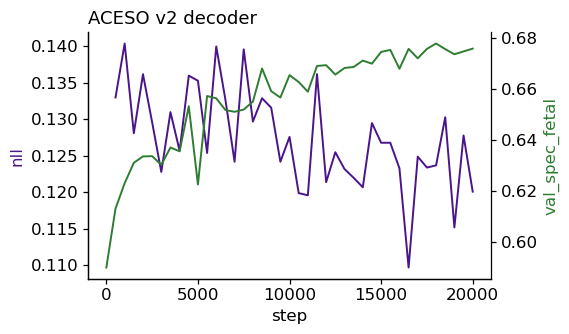

In [9]:
RUN = pathlib.Path(os.environ.get("ACESO_V2_RUN", ROOT / "aceso/runs/s2_D"))
if (RUN / "train.log").exists():
    df = aceso.read_training_log(RUN)
    fig, ax = aceso.plot_training_curve(RUN, keys=("nll", "val_spec_fetal"), show=False)
    ax[0].set_title("ACESO v2 decoder", loc="left", fontsize=13)
    print(df[[c for c in ("step", "nll", "dense", "contrast", "val_spec_fetal") if c in df]].tail(3)
          .to_string(index=False))
else:
    print(f"no run at {RUN}; set $ACESO_V2_RUN")

## Part 6 · Using a trained model

A checkpoint carries the exact configuration it was trained with, so a model found on disk can say
what it is without a separate record.

In [10]:
CKPT = pathlib.Path(os.environ.get("ACESO_V2_CKPT", ROOT / "aceso/runs/s2_C/final_step7937.pt"))
if CKPT.exists():
    try:
        import torch
        ck = torch.load(CKPT, map_location="cpu", weights_only=False)
        print(f"step {ck['step']}, state dimension {ck['z_dim']}, axes {list(ck.get('axes', []))}")
        print({k: ck["args"][k] for k in ("heads", "window", "bin", "cells_per_step", "freeze_trunk")})
    except ImportError:
        print("torch not installed in this environment; the checkpoint is at", CKPT)
else:
    print(f"no checkpoint at {CKPT}; set $ACESO_V2_CKPT")

step 7937, state dimension 516, axes ['chamber', 'cycle']
{'heads': 'atac,rna', 'window': 524288, 'bin': 32, 'cells_per_step': 32, 'freeze_trunk': True}


Prediction is `epi.models.aceso.predict_profiles`: DNA windows in, per-cell profiles out, averaged
over the forward and reverse-complement strands; `aggregate_regions` reduces them to peaks or
groups. A variant effect is the same call twice — reference and alternate sequence, same state — and
on the RNA head the difference in the per-gene rate is a direct expression prediction.

## Notes

* The encoder and decoder are separate jobs on purpose: stage 1 needs scGPT, stage 2 needs the
  AlphaGenome trunk and the fragment files, and they are rarely installed in one environment.
  `aceso.require_sites(...)` resolves every external path at start-up and fails there.
* Fragments are the ATAC target, so a sample with no fragment file contributes to stage 1 and not to
  stage 2. `TrainingStore.summary()` reports that split explicitly.
* The corpus is human. A model trained on it transfers to other genomes through the sequence trunk,
  but the states it knows are the ones its corpus contained — on a mouse embryo benchmark the v1
  model, trained on that organism, remains the better one.